<a href="https://colab.research.google.com/github/vaishnavidangi704-commits/CSL701-11_Machine-Learning-Lab/blob/main/Experiments%20and%20Mini-Project/ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name :

Batch :


Roll Number :



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extendedThe Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load dataset
url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/master/inst/extdata/penguins.csv"
df = pd.read_csv(url)

# Display dataset
print("First 5 rows of the dataset:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns)

First 5 rows of the dataset:
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  year  
0       3750.0    male  2007  
1       3800.0  female  2007  
2       3250.0  female  2007  
3          NaN     NaN  2007  
4       3450.0  female  2007  

Dataset shape: (344, 8)

Column names:
Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'year'],
      dtype='object')


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [2]:
# Select features and target
features = [
    'bill_length_mm',
    'bill_depth_mm',
    'flipper_length_mm',
    'body_mass_g'
]

target = 'species'

# Handle missing values
df = df[features + [target]].dropna()

# Select X and y
X = df[features]
y = df[target]

# Encode target labels
le = LabelEncoder()
y = le.fit_transform(y)

print("Features:")
print(X.head())

print("\nTarget classes:", le.classes_)
print("\nMissing values:")
print(X.isnull().sum())

Features:
   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0            39.1           18.7              181.0       3750.0
1            39.5           17.4              186.0       3800.0
2            40.3           18.0              195.0       3250.0
4            36.7           19.3              193.0       3450.0
5            39.3           20.6              190.0       3650.0

Target classes: ['Adelie' 'Chinstrap' 'Gentoo']

Missing values:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [3]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data size:", X_train.shape)
print("Testing data size:", X_test.shape)


Training data size: (273, 4)
Testing data size: (69, 4)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [4]:
# Create CART classifier using Gini Index
cart_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

# Train the model
cart_model.fit(X_train, y_train)

# Predict test data
y_pred_cart = cart_model.predict(X_test)

print("CART Classifier trained successfully.")

CART Classifier trained successfully.


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

CART Accuracy: 1.0

Confusion Matrix:
[[30  0  0]
 [ 0 14  0]
 [ 0  0 25]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



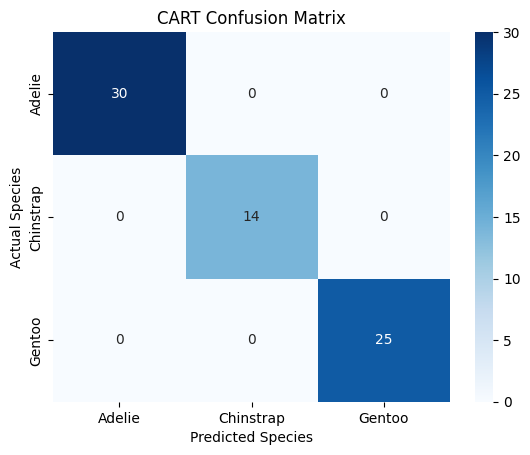

In [5]:
# Calculate accuracy
accuracy_cart = accuracy_score(y_test, y_pred_cart)
print("CART Accuracy:", accuracy_cart)

# Confusion matrix
cm_cart = confusion_matrix(y_test, y_pred_cart)
print("\nConfusion Matrix:")
print(cm_cart)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_cart,
    target_names=le.classes_,
    zero_division=0
))

# Visualize confusion matrix
sns.heatmap(
    cm_cart,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("CART Confusion Matrix")
plt.show()

# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


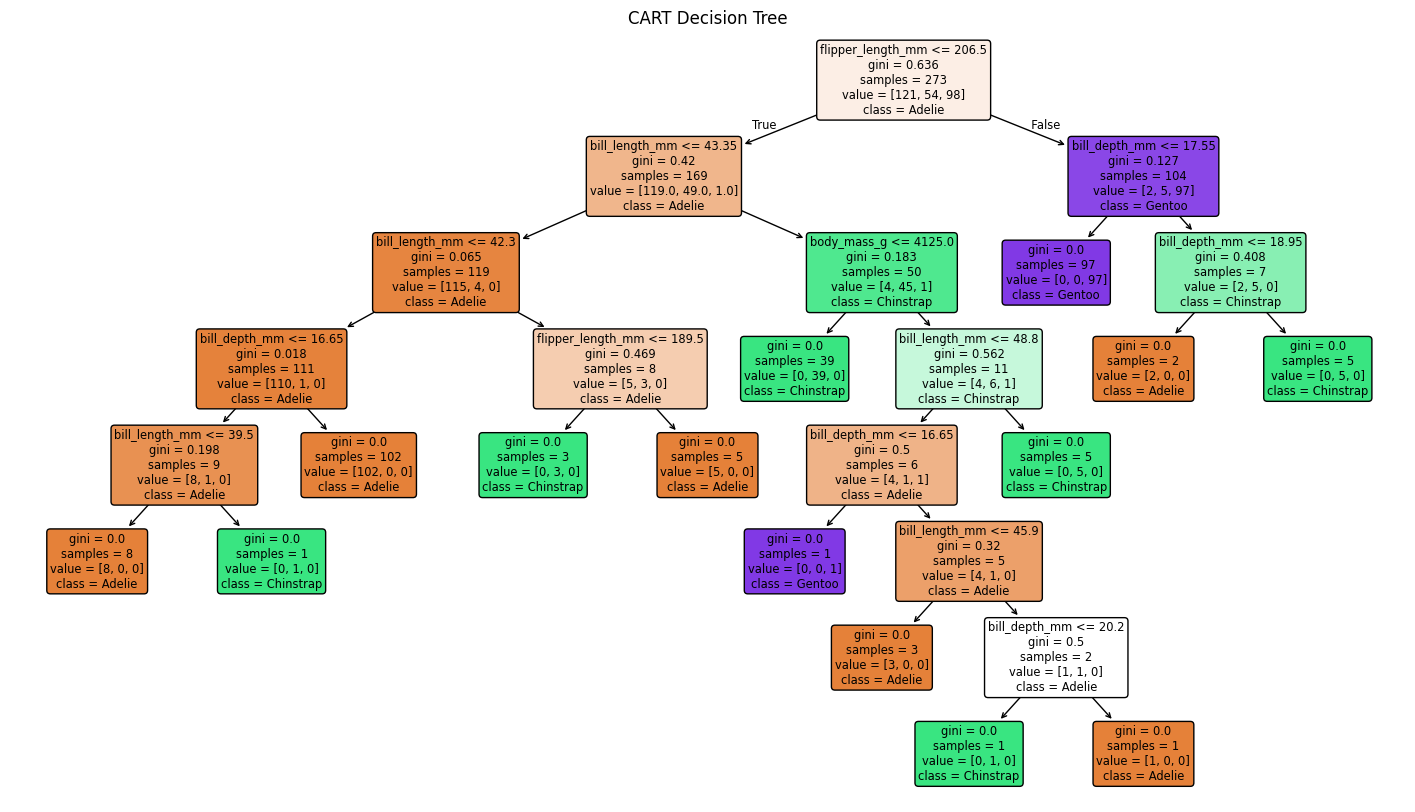

In [6]:
plt.figure(figsize=(18, 10))

plot_tree(
    cart_model,
    feature_names=features,
    class_names=le.classes_,
    filled=True,
    rounded=True
)

plt.title("CART Decision Tree")
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


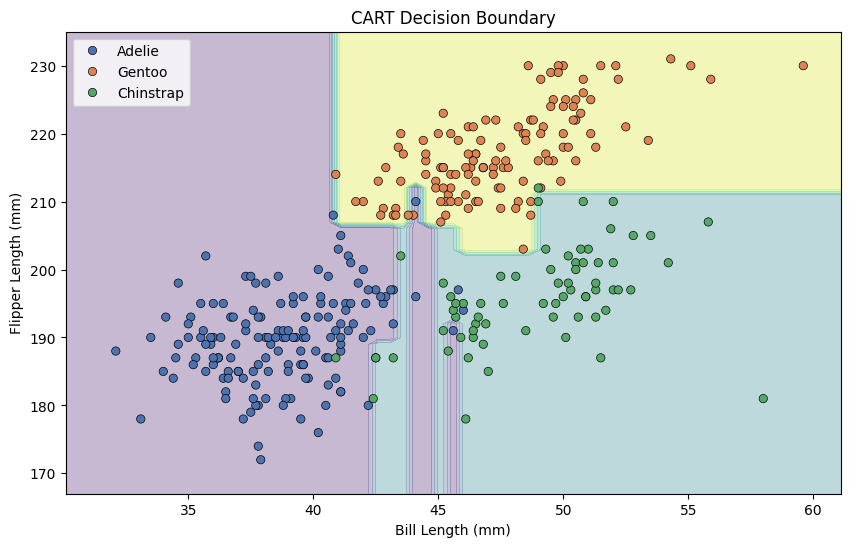

In [7]:
# Select two features
X_2d = df[['bill_length_mm', 'flipper_length_mm']]
y_2d = le.transform(df['species'])

# Train 2D decision tree
cart_2d = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

cart_2d.fit(X_2d, y_2d)

# Create mesh grid
x_min, x_max = X_2d.iloc[:, 0].min() - 2, X_2d.iloc[:, 0].max() + 2
y_min, y_max = X_2d.iloc[:, 1].min() - 5, X_2d.iloc[:, 1].max() + 5

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.5),
    np.arange(y_min, y_max, 1)
)

Z = cart_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundary
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')

sns.scatterplot(
    x=X_2d.iloc[:, 0],
    y=X_2d.iloc[:, 1],
    hue=le.inverse_transform(y_2d),
    palette='deep',
    edgecolor='black'
)

plt.xlabel("Bill Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.title("CART Decision Boundary")
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

Logistic Regression Accuracy: 0.9590643274853801


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


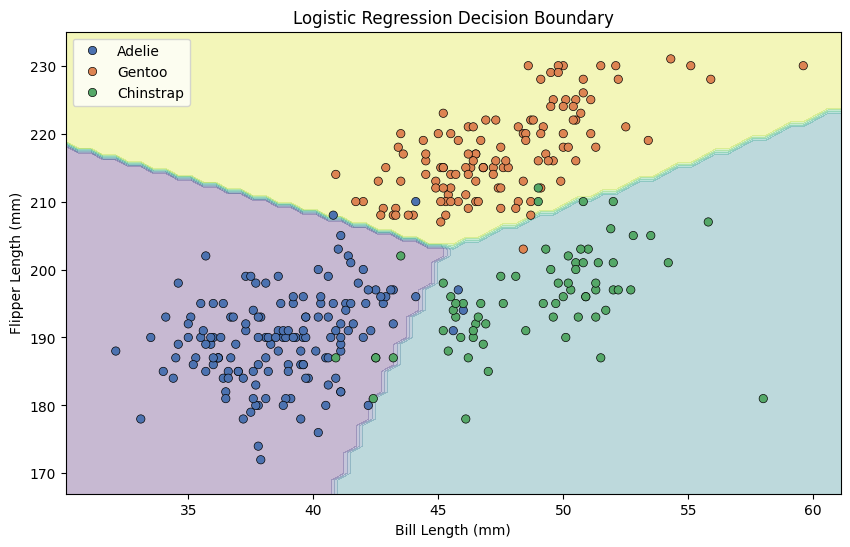

In [8]:
# Train Logistic Regression
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_2d, y_2d)

# Predict
y_pred_log = log_model.predict(X_2d)

# Calculate accuracy
accuracy_log = accuracy_score(y_2d, y_pred_log)
print("Logistic Regression Accuracy:", accuracy_log)

# Create mesh grid
Z_log = log_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z_log = Z_log.reshape(xx.shape)

# Plot linear classification boundary
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z_log, alpha=0.3, cmap='viridis')

sns.scatterplot(
    x=X_2d.iloc[:, 0],
    y=X_2d.iloc[:, 1],
    hue=le.inverse_transform(y_2d),
    palette='deep',
    edgecolor='black'
)

plt.xlabel("Bill Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.title("Logistic Regression Decision Boundary")
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


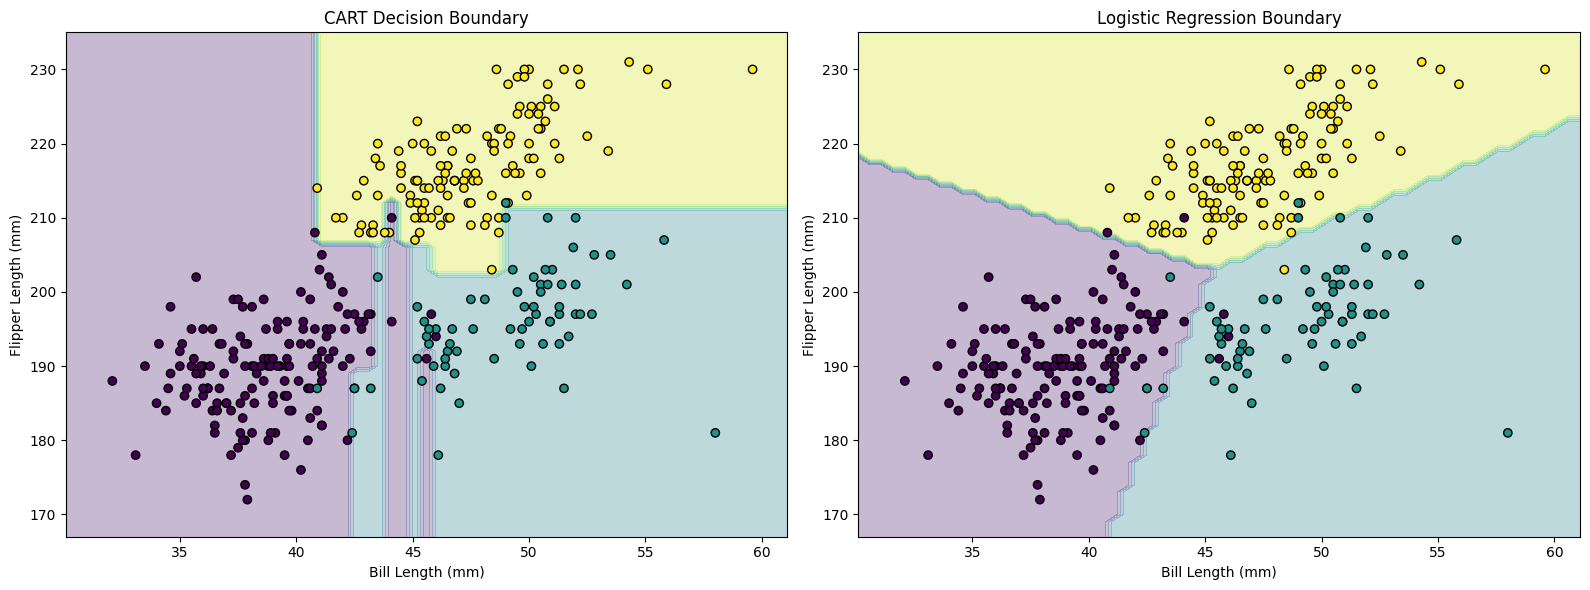

In [9]:
# Predict class regions for both models
Z_cart = cart_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z_cart = Z_cart.reshape(xx.shape)

Z_log = log_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z_log = Z_log.reshape(xx.shape)

# Side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# CART boundary
axes[0].contourf(xx, yy, Z_cart, alpha=0.3, cmap='viridis')
axes[0].scatter(
    X_2d.iloc[:, 0],
    X_2d.iloc[:, 1],
    c=y_2d,
    cmap='viridis',
    edgecolor='black'
)
axes[0].set_title("CART Decision Boundary")
axes[0].set_xlabel("Bill Length (mm)")
axes[0].set_ylabel("Flipper Length (mm)")

# Logistic Regression boundary
axes[1].contourf(xx, yy, Z_log, alpha=0.3, cmap='viridis')
axes[1].scatter(
    X_2d.iloc[:, 0],
    X_2d.iloc[:, 1],
    c=y_2d,
    cmap='viridis',
    edgecolor='black'
)
axes[1].set_title("Logistic Regression Boundary")
axes[1].set_xlabel("Bill Length (mm)")
axes[1].set_ylabel("Flipper Length (mm)")

plt.tight_layout()
plt.show()

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

CART Accuracy: 0.9420289855072463
Logistic Regression Accuracy: 0.9855072463768116

CART Confusion Matrix:
[[30  0  0]
 [ 3 11  0]
 [ 1  0 24]]

CART Classification Report:
              precision    recall  f1-score   support

      Adelie       0.88      1.00      0.94        30
   Chinstrap       1.00      0.79      0.88        14
      Gentoo       1.00      0.96      0.98        25

    accuracy                           0.94        69
   macro avg       0.96      0.92      0.93        69
weighted avg       0.95      0.94      0.94        69


Logistic Regression Confusion Matrix:
[[30  0  0]
 [ 1 13  0]
 [ 0  0 25]]

Logistic Regression Classification Report:
              precision    recall  f1-score   support

      Adelie       0.97      1.00      0.98        30
   Chinstrap       1.00      0.93      0.96        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.99      0.98      0.98        69


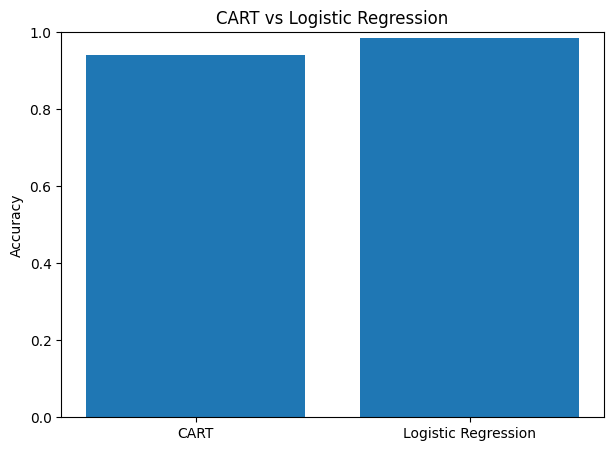

In [10]:
# Select two features for both models
X_train_2d = X_train[['bill_length_mm', 'flipper_length_mm']]
X_test_2d = X_test[['bill_length_mm', 'flipper_length_mm']]

# Train CART on 2D training data
cart_compare = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)
cart_compare.fit(X_train_2d, y_train)

# Train Logistic Regression on 2D training data
log_compare = LogisticRegression(max_iter=1000)
log_compare.fit(X_train_2d, y_train)

# Predictions
y_pred_cart_2d = cart_compare.predict(X_test_2d)
y_pred_log_2d = log_compare.predict(X_test_2d)

# Accuracy comparison
print("CART Accuracy:",
      accuracy_score(y_test, y_pred_cart_2d))

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_log_2d))

# CART evaluation
print("\nCART Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_cart_2d))

print("\nCART Classification Report:")
print(classification_report(
    y_test,
    y_pred_cart_2d,
    target_names=le.classes_,
    zero_division=0
))

# Logistic Regression evaluation
print("\nLogistic Regression Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_log_2d))

print("\nLogistic Regression Classification Report:")
print(classification_report(
    y_test,
    y_pred_log_2d,
    target_names=le.classes_,
    zero_division=0
))

# Accuracy comparison graph
models = ['CART', 'Logistic Regression']
accuracies = [
    accuracy_score(y_test, y_pred_cart_2d),
    accuracy_score(y_test, y_pred_log_2d)
]

plt.figure(figsize=(7, 5))
plt.bar(models, accuracies)
plt.ylabel("Accuracy")
plt.title("CART vs Logistic Regression")
plt.ylim(0, 1)
plt.show()

# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.